In [6]:
import os, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors

plt.rcParams['font.family'] = 'Malgun Gothic'   # Mac: 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False
pd.options.display.float_format = '{:,.2f}'.format
pd.options.display.width = 200

In [2]:
fam_place = pd.read_csv("제주 지역별 인기 장소.csv")

In [4]:
c = pd.read_csv("제주 지역별 차량 도착 수.csv")
v = pd.read_csv("제주 지역별 방문객.csv")
s = pd.read_csv("제주 지역별 소비 데이터.csv")
p = pd.read_csv("전국주차장정보표준데이터.csv", encoding="cp949")

C:\Users\82105\AppData\Local\Temp\ipykernel_36248\2575003032.py:4: DtypeWarning: Columns (20,32) have mixed types. Specify dtype option on import or set low_memory=False.
  p = pd.read_csv("전국주차장정보표준데이터.csv", encoding="cp949")


In [5]:
print(p.columns[[20, 32]])

Index(['추가단위요금', '제공기관코드'], dtype='object')


In [7]:
import os
import re
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Polygon as MplPolygon
from matplotlib.collections import PatchCollection
from matplotlib.path import Path
 
warnings.filterwarnings("ignore")
from matplotlib import font_manager
_avail = {f.name for f in font_manager.fontManager.ttflist}
for _f in ("Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK KR", "Noto Sans KR",
           "Noto Sans CJK JP", "Noto Sans CJK SC"):   # 설치된 한글 폰트 자동 선택
    if _f in _avail:
        plt.rcParams["font.family"] = _f
        break
plt.rcParams["axes.unicode_minus"] = False

In [8]:
DATA_DIR = os.environ.get("JEJU_DATA_DIR", ".")     # CSV 들이 있는 폴더
OUT_DIR = os.environ.get("JEJU_OUT_DIR", ".")       # 그림/표 저장 폴더
GEO_PATH = os.environ.get("JEJU_GEO_PATH", "jeju_emd.geojson")  # 없으면 버블 지도로 대체

In [9]:
def find_file(name):
    for d in (DATA_DIR, "."):
        for n in (name, name.replace(" ", "_")):
            pth = os.path.join(d, n)
            if os.path.exists(pth):
                return pth
    raise FileNotFoundError(name)
 
 
def read_any(name, **kw):
    pth = find_file(name)
    for enc in ("utf-8-sig", "utf-8", "cp949"):
        try:
            return pd.read_csv(pth, encoding=enc, **kw)
        except UnicodeDecodeError:
            continue
    raise UnicodeDecodeError("encoding", b"", 0, 1, f"{pth} 인코딩 확인 필요")

In [10]:
def prep(df):
    """공백 제거 + 연월 컬럼 통일 + 동 이름 정리 (기간은 이미 2023-01~2025-12로 맞춰져 있음)"""
    df = df.copy()
    df.columns = [re.sub(r"\s+", "", str(col)) for col in df.columns]
    ym = [col for col in df.columns if "YYYYMM" in col or col.endswith("연월")][0]
    df = df.rename(columns={ym: "연월"})
    df["연도"] = df["연월"] // 100
    df["읍면동명"] = df["읍면동명"].astype(str).str.strip()
    return df

In [11]:
c = prep(read_any("제주 지역별 차량 도착 수.csv"))
v = prep(read_any("제주 지역별 방문객.csv"))
s = prep(read_any("제주 지역별 소비 데이터.csv"))
fam_place = prep(read_any("제주 지역별 인기 장소.csv"))
p = read_any("전국주차장정보표준데이터.csv", low_memory=False)
v = v.rename(columns={col: "총방문객수" for col in v.columns if col.startswith("총방문객수")})
 
for k, d in {"c": c, "v": v, "s": s, "fam_place": fam_place}.items():
    print(f"[{k}] {d.shape} | {d['연월'].min()}~{d['연월'].max()} ({d['연월'].nunique()}개월) | 동 {d['읍면동명'].nunique()}개")
 
DONGS = sorted(c["읍면동명"].unique())
assert all(set(d["읍면동명"]) == set(DONGS) for d in (v, s, fam_place)), "데이터셋 간 읍면동명 불일치"
print("관광객구분:", s["관광객구분"].unique().tolist(), "| 업종:", s["업종명"].unique().tolist())

[c] (1548, 5) | 202301~202512 (36개월) | 동 43개
[v] (1548, 9) | 202301~202512 (36개월) | 동 43개
[s] (319123, 9) | 202301~202512 (36개월) | 동 43개
[fam_place] (846064, 10) | 202301~202512 (36개월) | 동 43개
관광객구분: ['도민', '내국인 관광객', '외국인 관광객'] | 업종: ['소매업', '숙박업', '음식점업', '기타서비스업', '예술스포츠여가업']


In [12]:
# %% [1] 인기장소: 관광 목적지만 추출 (피드백 1)
CAT = "카테고리3단계"
 
# 카테고리가 540여 개라 키워드 대신 실제 카테고리명으로 관광 목적지를 정의 (음식점·숙박·공항·주유소·병원 등은 제외)
TOUR_GROUPS = {
    "자연·트레킹": ["해수욕장", "명산", "오름", "폭포/계곡", "공원", "드라이브코스", "자연휴양림", "산림욕장",
                  "도립공원", "국립공원", "동굴", "섬", "포구", "등대", "전망대", "호수", "저수지", "염전",
                  "탐방코스", "고개/재/령", "약수터", "촬영지", "데이트코스", "방파제", "낚시"],
    "문화·전시": ["관광명소기타", "박물관/기념관", "전시장", "화랑/전시관", "미술관", "문화생활시설기타",
                "문화유적지", "고택/생가/민속마을", "절", "축제", "팝업/전시", "과학관", "탑", "성", "능묘",
                "기념비", "공연장", "관광안내소"],
    "테마·체험·레저": ["테마파크", "놀이공원", "동식물원", "수족관", "관광단지", "종합위락시설", "목장", "농장/농원",
                  "관광농원", "체험농가", "체험학습", "승마장", "온천", "캠프장", "여행/레저기타",
                  "레저/스포츠기타", "수상해양스포츠", "카레이싱장", "사격장", "서바이벌", "패러글라이딩",
                  "양궁/국궁", "유원지", "눈썰매장", "스케이트장", "자동차극장", "공방/공예", "특산물단지",
                  "과수원"],
}

In [13]:
# 판단이 갈리는 카테고리: 넣고 싶으면 아래 리스트에 추가 (예: "재래시장", "골프장", "카지노", "면세점", "이색카페")
OPTIONAL_INCLUDE = []
if OPTIONAL_INCLUDE:
    TOUR_GROUPS["기타(선택)"] = OPTIONAL_INCLUDE

In [14]:
TREK_CATS = ["명산", "오름", "폭포/계곡", "자연휴양림", "산림욕장", "도립공원", "국립공원", "탐방코스", "동굴", "고개/재/령"]

In [15]:
cat2group = {cat: g for g, cats in TOUR_GROUPS.items() for cat in cats}
missing = sorted(set(cat2group) - set(fam_place[CAT]))
print("데이터에 없는 카테고리명(오타 확인):", missing)
 
fam_place["관광그룹"] = fam_place[CAT].map(cat2group)
fam_place["관광여부"] = fam_place["관광그룹"].notna()
tour = fam_place[fam_place["관광여부"]].copy()
tour["트레킹여부"] = tour[CAT].isin(TREK_CATS)
 
print(f"\n관광 목적지로 분류된 카테고리 수: {tour[CAT].nunique()}개 / 목적지 수: {tour['목적지명'].nunique():,}개")
print(f"인기장소 전체 도착건수 중 관광 목적지 비율: {tour['도착건수'].sum() / fam_place['도착건수'].sum():.1%}"
      f" | 관광객 도착 기준: {tour['관광객도착수'].sum() / fam_place['관광객도착수'].sum():.1%}")
print("\n[관광 아님으로 분류된 카테고리 중 관광객 도착 TOP25 - 빠진 관광지가 없는지 확인]")
print(fam_place[~fam_place["관광여부"]].groupby(CAT)["관광객도착수"].sum().nlargest(25))
 

데이터에 없는 카테고리명(오타 확인): []

관광 목적지로 분류된 카테고리 수: 72개 / 목적지 수: 3,242개
인기장소 전체 도착건수 중 관광 목적지 비율: 18.5% | 관광객 도착 기준: 22.5%

[관광 아님으로 분류된 카테고리 중 관광객 도착 TOP25 - 빠진 관광지가 없는지 확인]
카테고리3단계
한식        3177997
호텔        1984288
카페기타      1650668
전문음식점     1009833
콘도/리조트     908461
렌트카        801901
재래시장       665380
펜션         546940
공항         526191
커피전문점      522659
주차장        414403
제과점        389521
대형슈퍼       387158
항구         372653
분식         292763
주유소        244292
골프장        217830
다이소        200333
패스트푸드      184752
대형마트       173498
쇼핑기타       168127
일식         126525
아파트단지      108246
전기차충전소     105721
가스충전소      103684
Name: 관광객도착수, dtype: int64


In [16]:
# %% [1-2] 관광 목적지 기준 EDA
tour_dong = tour.groupby("읍면동명").agg(
    관광지_관광객도착=("관광객도착수", "sum"),
    관광지_도민도착=("도민도착수", "sum"),
    관광지수=("목적지명", "nunique"),
).reindex(DONGS).fillna(0)
tour_dong["관광객비중"] = tour_dong["관광지_관광객도착"] / (tour_dong["관광지_관광객도착"] + tour_dong["관광지_도민도착"])
tour_dong["트레킹비중"] = (tour[tour["트레킹여부"]].groupby("읍면동명")["관광객도착수"].sum().reindex(DONGS).fillna(0)
                        / tour_dong["관광지_관광객도착"])
group_mix = (tour.pivot_table(index="읍면동명", columns="관광그룹", values="관광객도착수", aggfunc="sum")
             .reindex(DONGS).fillna(0))
group_share = group_mix.div(group_mix.sum(axis=1), axis=0)
tour_dong = tour_dong.join(group_share.add_suffix("_비중")).fillna(0)
tour_dong.index.name = "읍면동명"

[Text(0, 0, '202301'),
 Text(3, 0, '202304'),
 Text(6, 0, '202307'),
 Text(9, 0, '202310'),
 Text(12, 0, '202401'),
 Text(15, 0, '202404'),
 Text(18, 0, '202407'),
 Text(21, 0, '202410'),
 Text(24, 0, '202501'),
 Text(27, 0, '202504'),
 Text(30, 0, '202507'),
 Text(33, 0, '202510')]

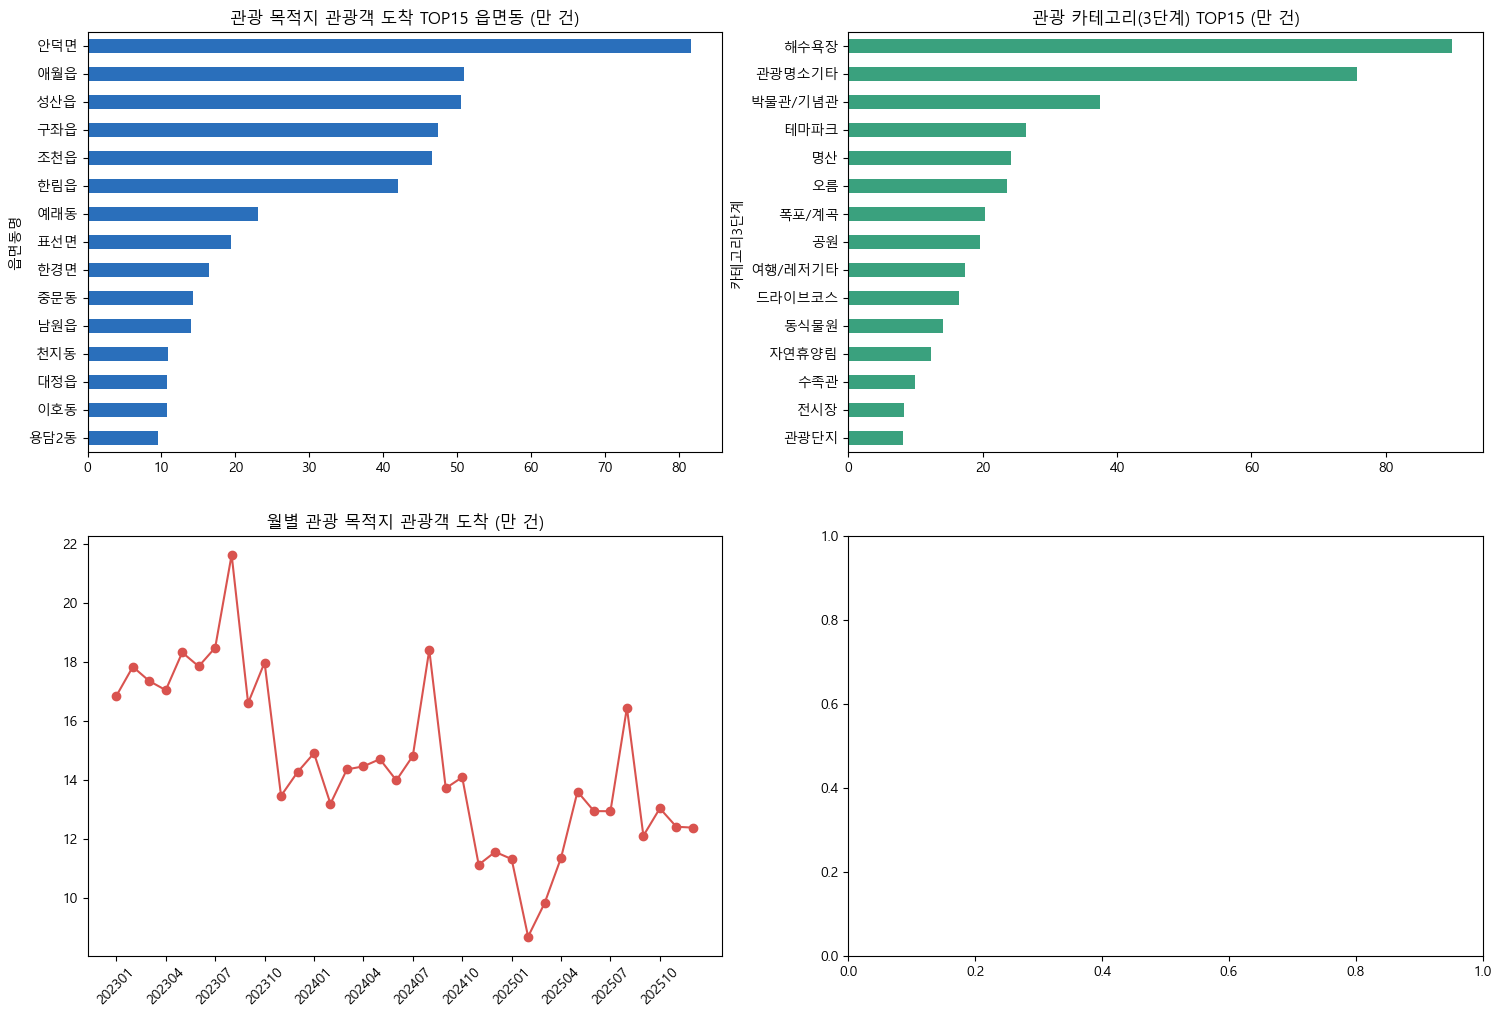

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(18, 12))
(tour_dong["관광지_관광객도착"].nlargest(15).sort_values() / 1e4).plot.barh(ax=axes[0, 0], color="#2a6fbb")
axes[0, 0].set_title("관광 목적지 관광객 도착 TOP15 읍면동 (만 건)")
 
(tour.groupby(CAT)["관광객도착수"].sum().nlargest(15).sort_values() / 1e4).plot.barh(ax=axes[0, 1], color="#3aa17e")
axes[0, 1].set_title("관광 카테고리(3단계) TOP15 (만 건)")
 
mon = tour.groupby("연월")["관광객도착수"].sum() / 1e4
axes[1, 0].plot(range(len(mon)), mon.values, marker="o", color="#d9534f")
axes[1, 0].set_title("월별 관광 목적지 관광객 도착 (만 건)")
axes[1, 0].set_xticks(range(0, len(mon), 3))
axes[1, 0].set_xticklabels(mon.index[::3], rotation=45)

In [18]:
top_order = tour_dong["관광지_관광객도착"].nlargest(15).index[::-1]
group_share.loc[top_order].plot.barh(stacked=True, ax=axes[1, 1], colormap="Set2")
axes[1, 1].set_title("관광 유형 구성 (관광객 도착 TOP15 동)")
axes[1, 1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.06), ncol=3, fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "eda1_tour_overview.png"), dpi=150)
plt.show()
 
print(tour.groupby(["읍면동명", "목적지명", CAT])["관광객도착수"].sum().nlargest(20).reset_index())

<Figure size 640x480 with 0 Axes>

   읍면동명          목적지명  카테고리3단계  관광객도착수
0   성산읍         성산일출봉       명산  168549
1   조천읍        함덕해수욕장     해수욕장  157211
2   한림읍        협재해수욕장     해수욕장  152074
3   안덕면       오설록티뮤지엄  박물관/기념관  119575
4   성산읍     아쿠아플라넷/제주      수족관   98703
5   성산읍          섭지코지   관광명소기타   97407
6   이호동        이호테우해변     해수욕장   86692
7   애월읍        곽지해수욕장     해수욕장   84624
8   안덕면         용머리해안   관광명소기타   78091
9   구좌읍           비자림    자연휴양림   74269
10  중문동         주상절리대   관광명소기타   70664
11  구좌읍        김녕해수욕장     해수욕장   70362
12  애월읍     아르떼뮤지엄/제주      전시장   69685
13  천지동         천지연폭포    폭포/계곡   66877
14  조천읍  한라산둘레길/사려니숲길  여행/레저기타   60802
15  한림읍           금오름       오름   59383
16  송산동          정방폭포    폭포/계곡   55544
17  예래동        중문색달해변     해수욕장   54577
18  안덕면       산방산탄산온천       온천   54087
19  한림읍        금능해수욕장     해수욕장   53852


In [19]:
# %% [2] 지도 준비 (피드백 2) - geopandas 없이 matplotlib 만으로 동작
NAME_KEYS = ["adm_nm", "ADM_NM", "EMD_KOR_NM", "emd_kor_nm", "name", "NAME"]
 
 
def load_geojson(path):
    """GeoJSON -> {읍면동명: [외곽선 좌표 배열, ...]}  (제주특별자치도 행정동만)"""
    with open(path, encoding="utf-8") as f:
        gj = json.load(f)
    geo = {}
    for ft in gj["features"]:
        props = ft["properties"]
        key = next((k for k in NAME_KEYS if k in props), None)
        full = str(props[key])
        if "특별자치도" in full or "광역시" in full or "특별시" in full or "도 " in full:
            if not full.startswith("제주"):
                continue
        name = full.split()[-1]
        g = ft["geometry"]
        polys = [g["coordinates"]] if g["type"] == "Polygon" else g["coordinates"]
        geo.setdefault(name, []).extend(np.array(poly[0]) for poly in polys)
    return geo

In [20]:
def ring_centroid(ring):
    x, y = ring[:, 0], ring[:, 1]
    a = x[:-1] * y[1:] - x[1:] * y[:-1]
    area = a.sum() / 2
    if abs(area) < 1e-12:
        return ring[:, 0].mean(), ring[:, 1].mean()
    return ((x[:-1] + x[1:]) * a).sum() / (6 * area), ((y[:-1] + y[1:]) * a).sum() / (6 * area)
 
 
GEO = load_geojson(GEO_PATH) if os.path.exists(GEO_PATH) else None
if GEO:
    print("경계 파일 로드:", len(GEO), "개 동 | 데이터에만 있는 동:", sorted(set(DONGS) - set(GEO)))
    GEO_CENT = {n: ring_centroid(max(rs, key=len)) for n, rs in GEO.items()}
else:
    print("경계 파일(GEO_PATH) 없음 -> 버블 지도로 대체 (읍면동 경계 지도를 원하면 GeoJSON 경로 지정)")

경계 파일(GEO_PATH) 없음 -> 버블 지도로 대체 (읍면동 경계 지도를 원하면 GeoJSON 경로 지정)


In [22]:
# --- 주차장: 제주 공영주차장 추출 + 읍면동 배정
addr = p["소재지도로명주소"].fillna("") + " " + p["소재지지번주소"].fillna("")
pj = p[addr.str.contains("제주")].copy()
pj["주차구획수"] = pd.to_numeric(pj["주차구획수"], errors="coerce")
pj = pj.dropna(subset=["위도", "경도"])
pj = pj[pj["위도"].between(33.0, 34.1) & pj["경도"].between(126.0, 127.1)].reset_index(drop=True)

In [23]:
if GEO:   # 경계 파일이 있으면 위경도 포함 여부로 배정 (행정동 기준으로 정확)
    pts = pj[["경도", "위도"]].values
    pj["읍면동명"] = None
    for name, rings in GEO.items():
        for ring in rings:
            hit = Path(ring).contains_points(pts) & pj["읍면동명"].isna().values
            pj.loc[hit, "읍면동명"] = name
    # 해안선 밖에 찍힌 점은 가장 가까운 동 중심으로
    un = pj["읍면동명"].isna()
    if un.any():
        names, cents = list(GEO_CENT), np.array(list(GEO_CENT.values()))
        d = ((pts[un.values][:, None, :] - cents[None]) ** 2).sum(-1)
        pj.loc[un, "읍면동명"] = [names[i] for i in d.argmin(1)]
else:     # 경계 파일이 없으면 인기장소 주소(법정동 -> 행정동 대응)로 근사 배정
    a = fam_place.drop_duplicates("목적지주소")[["목적지주소", "읍면동명"]]
    t = a["목적지주소"].str.split(expand=True)
    a["key"] = t[1] + " " + t[2]
    bjd2hjd = a.groupby("key")["읍면동명"].agg(lambda x: x.value_counts().idxmax())
    tp = pj["소재지지번주소"].fillna("").str.split(expand=True)
    pj["읍면동명"] = (tp[1] + " " + tp[2]).map(bjd2hjd)
    print(f"주차장 동 배정(주소 근사): {pj['읍면동명'].notna().mean():.1%} 배정 "
          "(서귀동처럼 한 법정동이 여러 행정동인 곳은 오차 가능 -> 경계 파일 권장)")

주차장 동 배정(주소 근사): 67.0% 배정 (서귀동처럼 한 법정동이 여러 행정동인 곳은 오차 가능 -> 경계 파일 권장)


In [24]:
parking_dong = (pj.dropna(subset=["읍면동명"]).groupby("읍면동명")
                .agg(주차장수=("주차장명", "count"), 총주차구획수=("주차구획수", "sum"),
                     lon=("경도", "mean"), lat=("위도", "mean"))
                .reindex(DONGS))
parking_dong["평균주차구획수"] = parking_dong["총주차구획수"] / parking_dong["주차장수"]
parking_dong[["주차장수", "총주차구획수"]] = parking_dong[["주차장수", "총주차구획수"]].fillna(0)
parking_dong.index.name = "읍면동명"
print(parking_dong.round(1).sort_values("총주차구획수", ascending=False).head(10))

       주차장수   총주차구획수    lon   lat  평균주차구획수
읍면동명                                      
이도2동 139.00 2,914.00 126.50 33.50    21.00
노형동   83.00 2,575.00 126.50 33.50    31.00
성산읍   13.00 2,278.00 126.90 33.50   175.20
아라동   84.00 1,568.00 126.50 33.50    18.70
애월읍  102.00 1,475.00 126.40 33.50    14.50
구좌읍   45.00 1,456.00 126.80 33.50    32.40
조천읍   57.00 1,401.00 126.70 33.50    24.60
중앙동   14.00 1,331.00 126.60 33.20    95.10
연동    37.00 1,233.00 126.50 33.50    33.30
동홍동   11.00 1,075.00 126.60 33.30    97.70


In [25]:
# --- 지도 그리기 함수 (경계 있으면 단계구분도, 없으면 버블)
BG = pj[["경도", "위도"]].values
 
 
def jeju_map(df, col, title, cmap="YlOrRd", center_zero=False, topn=5, ax=None, fname=None, fmt="{:.1f}"):
    """df 의 index 는 읍면동명. 값이 클수록 진하게, 상위 topn 동 이름 표시"""
    vals = df[col].reindex(DONGS)
    own = ax is None
    if own:
        _, ax = plt.subplots(figsize=(10, 6.5))
    vmax = np.nanmax(np.abs(vals)) if center_zero else np.nanmax(vals)
    vmin = -vmax if center_zero else np.nanmin(vals)
    cm = plt.get_cmap(cmap).copy()
    cm.set_bad("#dddddd")
 
    if GEO:
        patches, arr = [], []
        for n in DONGS:
            for ring in GEO.get(n, []):
                patches.append(MplPolygon(ring, closed=True))
                arr.append(vals[n])
        pc = PatchCollection(patches, cmap=cm, edgecolor="white", linewidth=0.4)
        pc.set_array(np.ma.masked_invalid(np.array(arr)))
        pc.set_clim(vmin, vmax)
        ax.add_collection(pc)
        mappable = pc
        cent = GEO_CENT
    else:
        ax.scatter(BG[:, 0], BG[:, 1], s=3, c="#cccccc", zorder=1)      # 주차장 위치로 섬 윤곽 표현
        cent = parking_dong[["lon", "lat"]].dropna().T.to_dict("list")
        xy = np.array([cent[n] for n in DONGS if n in cent])
        names_ok = [n for n in DONGS if n in cent]
        mappable = ax.scatter(xy[:, 0], xy[:, 1], c=vals[names_ok], s=170, cmap=cm, vmin=vmin, vmax=vmax,
                              edgecolor="k", linewidth=0.6, zorder=3)
 
    if not GEO:
        no_xy = [n for n in DONGS if n not in cent]
        if no_xy and own:
            print("버블 지도에서 좌표를 못 찾아 빠진 동:", no_xy, "-> 경계 GeoJSON 사용 권장")
    for n in vals.nlargest(topn).index:
        if n in cent:
            ax.annotate(f"{n}", cent[n], ha="center", va="center", fontsize=9, fontweight="bold", zorder=5,
                        bbox=dict(boxstyle="round,pad=0.15", fc="white", alpha=0.75, lw=0))
    plt.colorbar(mappable, ax=ax, shrink=0.6)
    ax.set_xlim(126.1, 127.0)
    ax.set_ylim(33.1, 33.6)
    ax.set_aspect(1 / np.cos(np.radians(33.4)))
    ax.set_axis_off()
    ax.set_title(title, fontsize=13)
    if own:
        plt.tight_layout()
        if fname:
            plt.savefig(os.path.join(OUT_DIR, fname), dpi=150)
        plt.show()

버블 지도에서 좌표를 못 찾아 빠진 동: ['영천동', '예래동', '정방동', '천지동'] -> 경계 GeoJSON 사용 권장


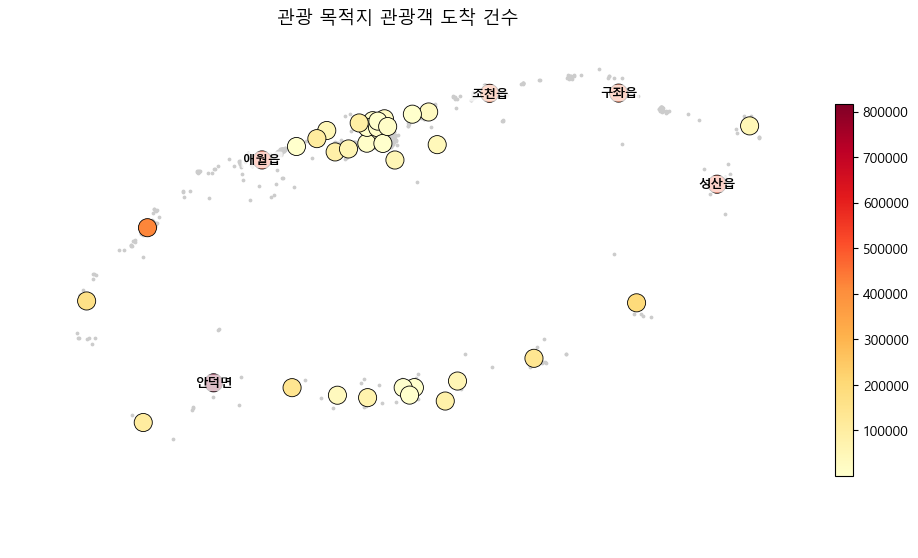

버블 지도에서 좌표를 못 찾아 빠진 동: ['영천동', '예래동', '정방동', '천지동'] -> 경계 GeoJSON 사용 권장


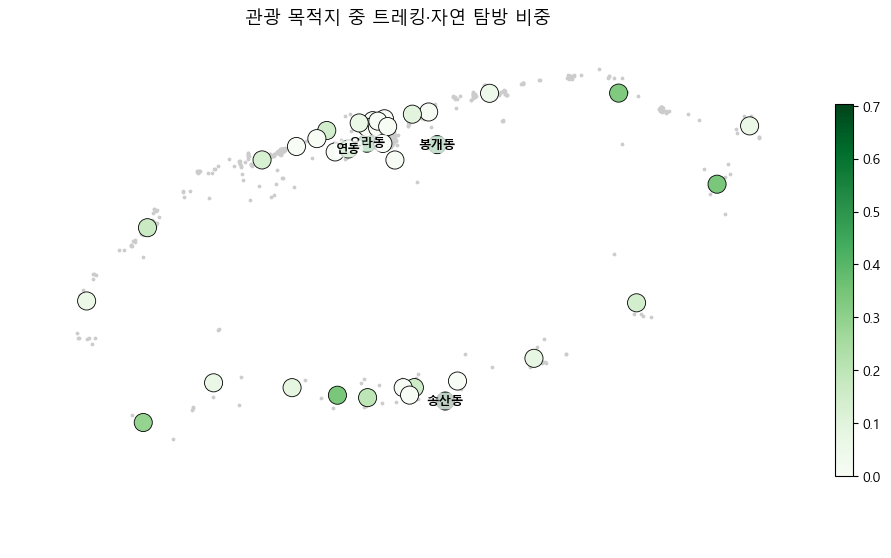

버블 지도에서 좌표를 못 찾아 빠진 동: ['영천동', '예래동', '정방동', '천지동'] -> 경계 GeoJSON 사용 권장


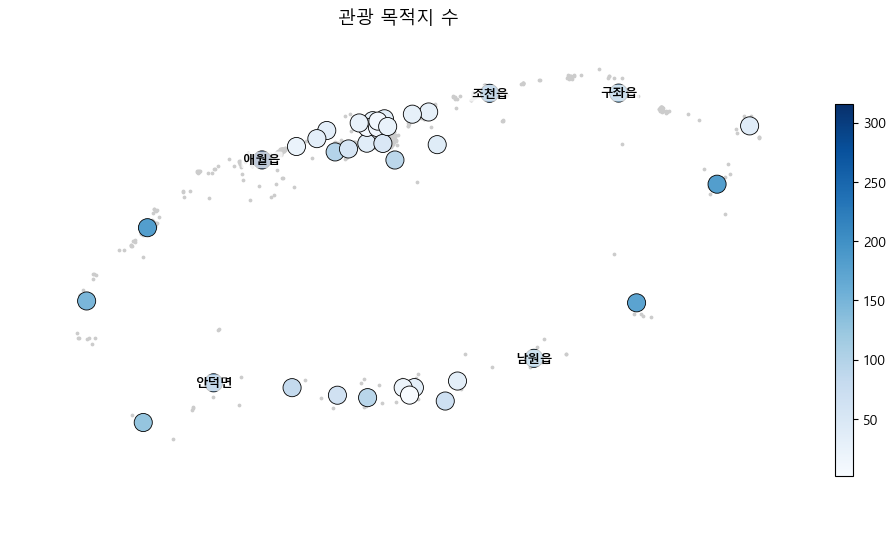

버블 지도에서 좌표를 못 찾아 빠진 동: ['영천동', '예래동', '정방동', '천지동'] -> 경계 GeoJSON 사용 권장


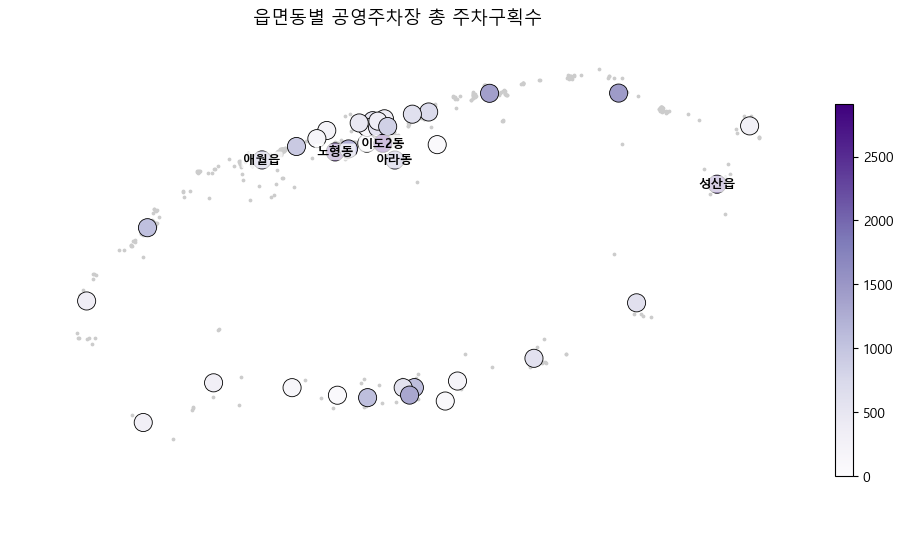

소비 비중(원):
 관광객구분
내국인 관광객   0.43
도민        0.49
외국인 관광객   0.08
Name: 소비금액(원), dtype: float64
(참고) 도민 포함 전체 소비 기준 vs 관광객 소비 기준 동별 순위상관: 0.825


In [26]:
# --- 관광 목적지 EDA 지도
jeju_map(tour_dong, "관광지_관광객도착", "관광 목적지 관광객 도착 건수", fname="map_tour_arrival.png")
jeju_map(tour_dong, "트레킹비중", "관광 목적지 중 트레킹·자연 탐방 비중", cmap="Greens", fname="map_trekking.png")
jeju_map(tour_dong, "관광지수", "관광 목적지 수", cmap="Blues", fname="map_tour_count.png")
jeju_map(parking_dong, "총주차구획수", "읍면동별 공영주차장 총 주차구획수", cmap="Purples", fname="map_parking.png")
 
# %% [3] 미스매치 지수 신뢰성 검증 (피드백 3)
# 소비 데이터에는 '도민' 소비가 약 49% 포함돼 있음. 중간발표 원안은 '티맵 도착건수 x 관광객(내·외국인) 소비'로 계산했을 때
# 슬라이드의 상위 목록(애월·구좌·한림·아라·성산·조천)이 그대로 재현되므로, 이를 원안(M1)으로 둠
s["관광객여부"] = s["관광객구분"].isin(["내국인 관광객", "외국인 관광객"])
print("소비 비중(원):\n", (s.groupby("관광객구분")["소비금액(원)"].sum() / s["소비금액(원)"].sum()).round(3))
print("(참고) 도민 포함 전체 소비 기준 vs 관광객 소비 기준 동별 순위상관:",
      round(s.groupby("읍면동명")["소비금액(원)"].sum().corr(
          s[s["관광객여부"]].groupby("읍면동명")["소비금액(원)"].sum(), method="spearman"), 3))

In [27]:
def make_base(years=None):
    sel = (lambda df: df) if years is None else (lambda df: df[df["연도"].isin(years)])
    b = pd.DataFrame({
        "traffic": sel(c).groupby("읍면동명")["도착건수"].sum(),                               # 티맵 도착(전체 차량)
        "visitors": sel(v).groupby("읍면동명")["총방문객수"].sum(),                            # SKT 방문객
        "tour_traffic": sel(tour).groupby("읍면동명")["관광객도착수"].sum(),                   # 관광지 관광객 도착
        "spend": sel(s).groupby("읍면동명")["소비금액(원)"].sum(),                             # 카드 소비(도민 포함)
        "spend_tourist": sel(s[s["관광객여부"]]).groupby("읍면동명")["소비금액(원)"].sum(),     # 관광객 소비
        "spend_tourist_nolodge": sel(s[s["관광객여부"] & (s["업종명"] != "숙박업")])
                                 .groupby("읍면동명")["소비금액(원)"].sum(),                   # 관광객 소비 - 숙박업
    }).reindex(DONGS).fillna(0)
    b.index.name = "읍면동명"
    return b

In [28]:
def z(x):
    return (x - x.mean()) / x.std(ddof=0)
 
 
def rz(x):                                    # 로버스트 Z (중앙값/MAD)
    med = x.median()
    return (x - med) / ((x - med).abs().median() * 1.4826)

In [29]:
def build_indices(b):
    """모든 지수: 값이 클수록 '트래픽 대비 소비가 낮은' 통과형"""
    L = lambda col: np.log1p(b[col])
    idx = pd.DataFrame(index=b.index)
    idx["M1_원안(Z차이)"] = z(b["traffic"]) - z(b["spend_tourist"])
    idx["M2_로그Z차이"] = z(L("traffic")) - z(L("spend_tourist"))
    idx["M3_로버스트Z"] = rz(L("traffic")) - rz(L("spend_tourist"))
    idx["M4_백분위차이"] = b["traffic"].rank(pct=True) - b["spend_tourist"].rank(pct=True)
    slope, icpt = np.polyfit(L("traffic"), L("spend_tourist"), 1)    # log관광객소비 ~ log트래픽 회귀
    resid = L("spend_tourist") - (slope * L("traffic") + icpt)
    idx["M5_회귀잔차"] = -(resid / resid.std(ddof=0))
    idx["M6_관광객정합"] = z(L("tour_traffic")) - z(L("spend_tourist"))          # 관광객 트래픽 vs 관광객 소비
    idx["M7_SKT방문객"] = z(L("visitors")) - z(L("spend_tourist"))               # 독립 트래픽 지표(SKT)
    idx["M8_도착당소비(역)"] = -z(L("spend_tourist") - L("tour_traffic"))
    idx["M9_숙박제외"] = z(L("tour_traffic")) - z(L("spend_tourist_nolodge"))   # 체류(숙박) 소비 제외
    return idx

In [30]:
base = make_base()
idx = build_indices(base)
rank_df = idx.rank(ascending=False)      # 1위 = 가장 통과형
K = 10
print(base.corr(method="spearman").round(2))
print(idx.round(2).sort_values("M1_원안(Z차이)", ascending=False).head(12))

                       traffic  visitors  tour_traffic  spend  spend_tourist  spend_tourist_nolodge
traffic                   1.00      0.89          0.68   0.86           0.93                   0.94
visitors                  0.89      1.00          0.75   0.76           0.91                   0.91
tour_traffic              0.68      0.75          1.00   0.44           0.61                   0.62
spend                     0.86      0.76          0.44   1.00           0.82                   0.84
spend_tourist             0.93      0.91          0.61   0.82           1.00                   0.98
spend_tourist_nolodge     0.94      0.91          0.62   0.84           0.98                   1.00
      M1_원안(Z차이)  M2_로그Z차이  M3_로버스트Z  M4_백분위차이  M5_회귀잔차  M6_관광객정합  M7_SKT방문객  M8_도착당소비(역)  M9_숙박제외
읍면동명                                                                                              
애월읍         1.69     -0.06      0.20      0.12    -0.49     -0.04       0.42         0.80    -0.19
구좌읍

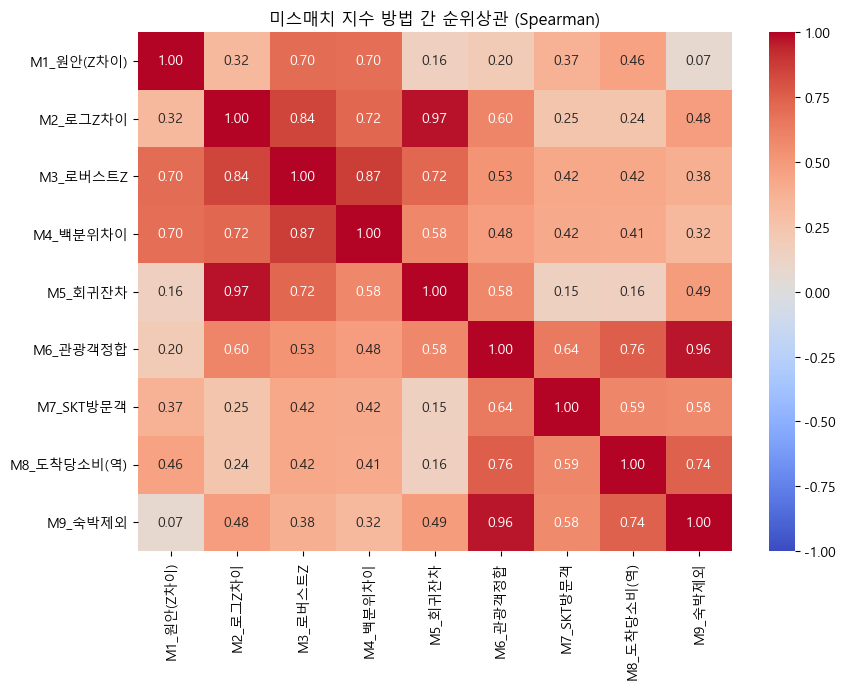


[상위 10개 동 겹침 수 - 원안(M1) 대비]
 M1_원안(Z차이)     10
M2_로그Z차이        1
M3_로버스트Z        4
M4_백분위차이        3
M5_회귀잔차         1
M6_관광객정합        0
M7_SKT방문객       6
M8_도착당소비(역)     4
M9_숙박제외         0
Name: M1_원안(Z차이), dtype: int64


In [31]:
# 3-1. 방법 간 순위 일치도
corr = idx.corr(method="spearman")
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("미스매치 지수 방법 간 순위상관 (Spearman)")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "mismatch_method_corr.png"), dpi=150)
plt.show()
 
top_sets = {m: set(rank_df.index[rank_df[m] <= K]) for m in idx.columns}
overlap = pd.DataFrame({m: {n: len(top_sets[m] & top_sets[n]) for n in idx.columns} for m in idx.columns})
print(f"\n[상위 {K}개 동 겹침 수 - 원안(M1) 대비]\n", overlap["M1_원안(Z차이)"])

In [32]:
# 3-2. 규모 편향 점검: 지수가 단순히 '큰 동'을 잡아내는지
size_bias = idx.apply(lambda col: col.corr(np.log1p(base["traffic"]), method="spearman"))
print("\n[트래픽 규모와의 순위상관 - 0에 가까울수록 규모 중립]\n", size_bias.round(2))


[트래픽 규모와의 순위상관 - 0에 가까울수록 규모 중립]
 M1_원안(Z차이)     0.58
M2_로그Z차이      -0.37
M3_로버스트Z       0.09
M4_백분위차이       0.16
M5_회귀잔차       -0.52
M6_관광객정합      -0.33
M7_SKT방문객      0.05
M8_도착당소비(역)    0.25
M9_숙박제외       -0.34
dtype: float64


In [33]:
# 3-3. 연도별 안정성
years = sorted(c["연도"].unique())
for m in ["M1_원안(Z차이)", "M5_회귀잔차"]:
    yearly = pd.DataFrame({y: build_indices(make_base([y]))[m] for y in years})
    print(f"\n[연도별 순위상관 - {m}]\n", yearly.corr(method="spearman").round(2))


[연도별 순위상관 - M1_원안(Z차이)]
       2023  2024  2025
2023  1.00  0.96  0.89
2024  0.96  1.00  0.96
2025  0.89  0.96  1.00

[연도별 순위상관 - M5_회귀잔차]
       2023  2024  2025
2023  1.00  0.97  0.92
2024  0.97  1.00  0.97
2025  0.92  0.97  1.00


In [34]:
# 3-4. 월 단위 부트스트랩: 월을 복원추출해 지수를 반복 계산 -> 상위 K 포함 확률
months = sorted(c["연월"].unique())
 
 
def monthly_mat(df, val):
    return (df.pivot_table(index="읍면동명", columns="연월", values=val, aggfunc="sum")
            .reindex(index=DONGS, columns=months).fillna(0).values)
 
 
T, S = monthly_mat(c, "도착건수"), monthly_mat(s[s["관광객여부"]], "소비금액(원)")
zn = lambda x: (x - x.mean()) / x.std()
rng = np.random.default_rng(42)
B = 1000
cnt1, cnt5 = np.zeros(len(DONGS)), np.zeros(len(DONGS))
for _ in range(B):
    ids = rng.integers(0, len(months), len(months))
    t, sp = T[:, ids].sum(1), S[:, ids].sum(1)
    m1 = zn(t) - zn(sp)
    lt, ls = np.log1p(t), np.log1p(sp)
    a, b0 = np.polyfit(lt, ls, 1)
    m5 = -(ls - (a * lt + b0))
    cnt1[np.argsort(-m1)[:K]] += 1
    cnt5[np.argsort(-m5)[:K]] += 1
boot1 = pd.Series(cnt1 / B, index=DONGS)
boot5 = pd.Series(cnt5 / B, index=DONGS)


[합의 결과 (방법 9개, 상위 10 기준)]
       합의지수_평균Z  평균순위  상위K포함_방법수  부트스트랩_원안  부트스트랩_회귀잔차  합의_통과형
읍면동명                                                         
한경면       0.92  5.67          8      0.00        1.00    True
아라동       1.08  7.33          6      1.00        1.00    True
삼양동       1.06  7.44          6      0.00        1.00    True
효돈동       0.96  8.50          6      0.00        1.00    True
천지동       0.68 10.06          6      0.00        0.63    True
구좌읍       0.84  8.89          5      1.00        0.00   False
서홍동       0.59 14.83          5      0.00        1.00   False
동홍동       0.50 16.00          4      0.00        1.00   False
애월읍       0.59 16.78          4      1.00        0.00   False
오라동       0.27 17.50          4      0.00        0.98   False
이호동       0.56 12.50          3      0.00        0.03   False
대정읍       0.44 14.61          3      1.00        0.00   False
한림읍       0.45 14.83          3      1.00        0.00   False
송산동       0.35 18.11          3      0.00 

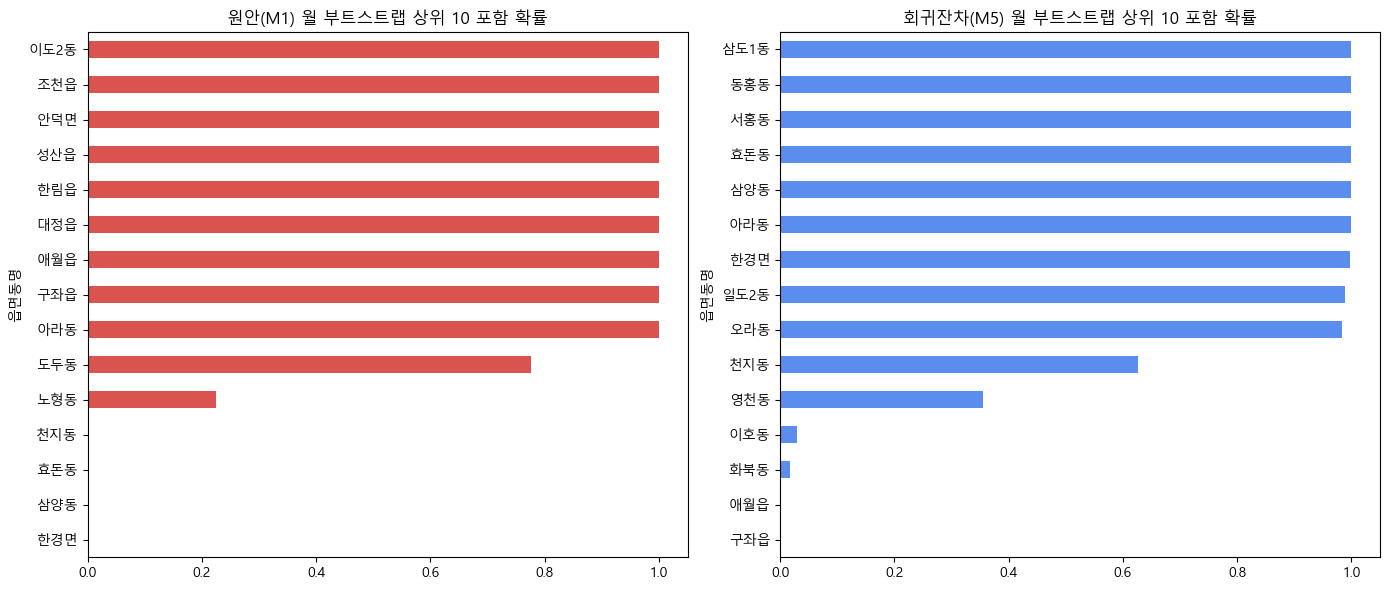

In [35]:
# 3-5. 합의(consensus) 지수
cons = pd.DataFrame({
    "합의지수_평균Z": idx.apply(z).mean(axis=1),
    "평균순위": rank_df.mean(axis=1),
    "상위K포함_방법수": (rank_df <= K).sum(axis=1),
    "부트스트랩_원안": boot1,
    "부트스트랩_회귀잔차": boot5,
})
n_methods = idx.shape[1]
cons["합의_통과형"] = cons["상위K포함_방법수"] >= int(np.ceil(0.6 * n_methods))    # 60% 이상 방법에서 상위 K
cons = cons.sort_values(["상위K포함_방법수", "평균순위"], ascending=[False, True])
cons.index.name = "읍면동명"
print(f"\n[합의 결과 (방법 {n_methods}개, 상위 {K} 기준)]\n", cons.head(15).round(2))
 
prev = ["애월읍", "구좌읍", "한림읍", "성산읍", "조천읍"]     # 중간발표 때 도출한 후보
print("\n중간발표 후보 중 합의 통과형으로 유지:", [d for d in prev if cons.loc[d, "합의_통과형"]])
print("중간발표 후보 중 합의에서 탈락:", [d for d in prev if not cons.loc[d, "합의_통과형"]])
print("새로 합의에 들어온 동:", [d for d in cons.index[cons["합의_통과형"]] if d not in prev])
 
eda1 = ["효돈동", "한경면", "천지동", "영천동", "용담1동"]      # 중간발표 EDA 1 (소비 잔차 기준) 후보
print("\nEDA1 후보 중 합의 통과형:", [d for d in eda1 if cons.loc[d, "합의_통과형"]])
print("EDA1 후보 상위K 포함 방법수:", cons.loc[eda1, "상위K포함_방법수"].to_dict())
 
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
cons["부트스트랩_원안"].nlargest(15).sort_values().plot.barh(ax=axes[0], color="#d9534f")
axes[0].set_title(f"원안(M1) 월 부트스트랩 상위 {K} 포함 확률")
cons["부트스트랩_회귀잔차"].nlargest(15).sort_values().plot.barh(ax=axes[1], color="#5b8def")
axes[1].set_title(f"회귀잔차(M5) 월 부트스트랩 상위 {K} 포함 확률")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "mismatch_bootstrap.png"), dpi=150)
plt.show()
 

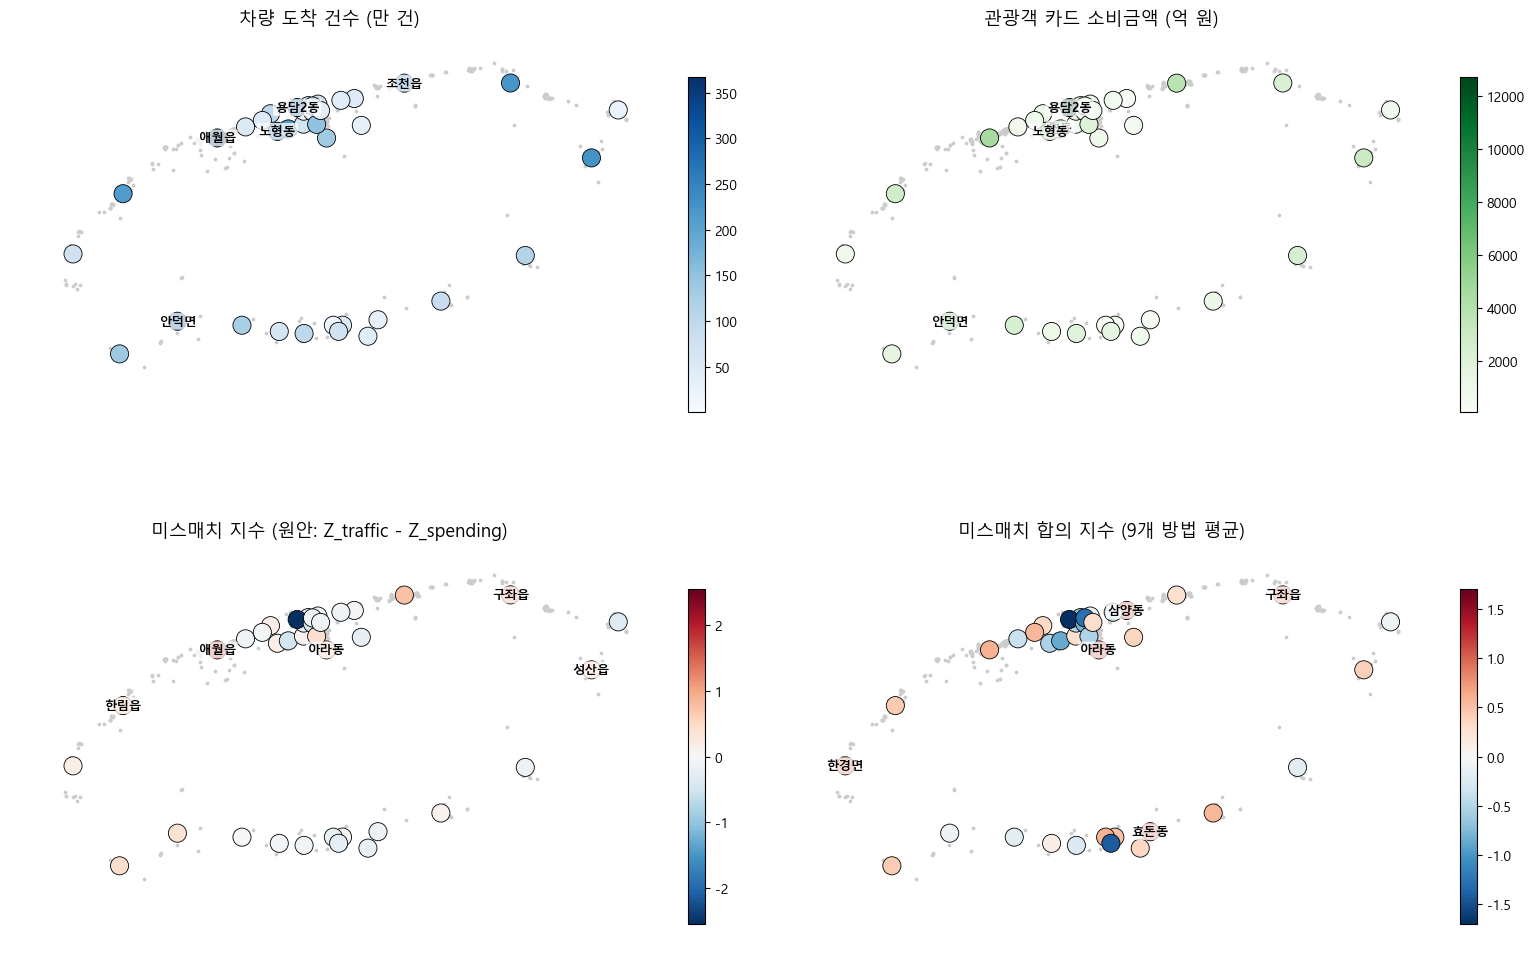

버블 지도에서 좌표를 못 찾아 빠진 동: ['영천동', '예래동', '정방동', '천지동'] -> 경계 GeoJSON 사용 권장


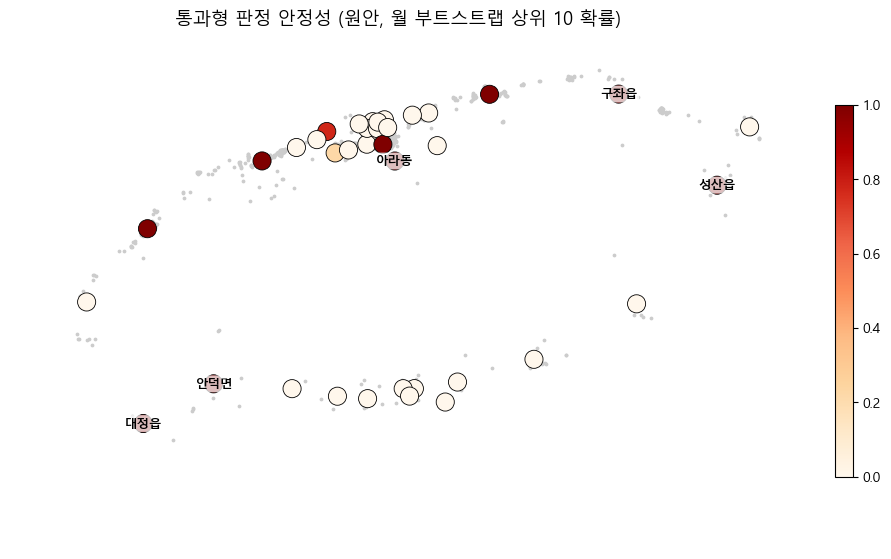

(43, 23)


In [36]:
# %% [4] 지도로 결과 보여주기
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
jeju_map(base.assign(v=base["traffic"] / 1e4), "v", "차량 도착 건수 (만 건)", cmap="Blues", ax=axes[0, 0])
jeju_map(base.assign(v=base["spend_tourist"] / 1e8), "v", "관광객 카드 소비금액 (억 원)", cmap="Greens", ax=axes[0, 1])
jeju_map(idx, "M1_원안(Z차이)", "미스매치 지수 (원안: Z_traffic - Z_spending)", cmap="RdBu_r",
         center_zero=True, ax=axes[1, 0])
jeju_map(cons, "합의지수_평균Z", f"미스매치 합의 지수 ({n_methods}개 방법 평균)", cmap="RdBu_r",
         center_zero=True, ax=axes[1, 1])
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "map_mismatch_panel.png"), dpi=150)
plt.show()
 
jeju_map(cons, "부트스트랩_원안", f"통과형 판정 안정성 (원안, 월 부트스트랩 상위 {K} 확률)", cmap="OrRd",
         fname="map_mismatch_confidence.png")
 
# %% [5] 이후 클러스터링용 통합 테이블 저장
final = (base.join(tour_dong, how="left").join(parking_dong.drop(columns=["lon", "lat"]), how="left")
         .join(cons, how="left"))
final.to_csv(os.path.join(OUT_DIR, "jeju_dong_base_table.csv"), encoding="utf-8-sig")
cons.to_csv(os.path.join(OUT_DIR, "mismatch_consensus.csv"), encoding="utf-8-sig")
print(final.shape)